# Section 2: One-hot encoding, Logistic Regression & saving the model
Churn prediction project. The explanations for every step are on the Notion page for this section.

## Loading the clean data

In [1]:
# change these paths if you saved the files somewhere else
DATA_PATH = 'Section 1 autumn 2027telco_churn_clean.csv'
MODEL_PATH = 'model/churn_predictor'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv(DATA_PATH)

df_train, df_val = train_test_split(df, test_size=0.2, random_state=42)

len(df_train), len(df_val)

(5634, 1409)

In [7]:
y_train = df_train.churn.values
y_val = df_val.churn.values

y_train

array([0, 0, 1, ..., 0, 1, 0], shape=(5634,))

In [4]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = ['seniorcitizen', 'partner', 'dependents',
              'internetservice','onlinesecurity',
              'onlinebackup', 'deviceprotection', 'techsupport',
              'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
              'paymentmethod']

## One-hot encoding
### From a DataFrame to a list of dictionaries

In [5]:
# one dictionary per column: not what we want
df_train[['gender', 'contract']].iloc[:3].to_dict()

{'gender': {2142: 'female', 1623: 'female', 6074: 'male'},
 'contract': {2142: 'one_year', 1623: 'two_year', 6074: 'month-to-month'}}

In [6]:
# one dictionary per customer
dicts = df_train[['gender', 'contract']].iloc[:5].to_dict(orient='records')
dicts

[{'gender': 'female', 'contract': 'one_year'},
 {'gender': 'female', 'contract': 'two_year'},
 {'gender': 'male', 'contract': 'month-to-month'},
 {'gender': 'male', 'contract': 'month-to-month'},
 {'gender': 'male', 'contract': 'two_year'}]

### DictVectorizer

In [7]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer()
dv.fit(dicts)

dv.transform(dicts)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10 stored elements and shape (5, 5)>

In [8]:
dv = DictVectorizer(sparse=False)
dv.fit(dicts)

dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'gender=female', 'gender=male'], dtype=object)

In [9]:
dv.transform(dicts)

array([[0., 1., 0., 1., 0.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 0., 1.],
       [1., 0., 0., 0., 1.],
       [0., 0., 1., 0., 1.]])

### Bringing it all together

In [10]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
train_dicts[0]

{'seniorcitizen': 0,
 'partner': 'no',
 'dependents': 'yes',
 'internetservice': 'dsl',
 'onlinesecurity': 'yes',
 'onlinebackup': 'no',
 'deviceprotection': 'yes',
 'techsupport': 'no',
 'streamingtv': 'no',
 'streamingmovies': 'yes',
 'contract': 'one_year',
 'paperlessbilling': 'no',
 'paymentmethod': 'mailed_check',
 'tenure': 21,
 'monthlycharges': 64.85,
 'totalcharges': 1336.8}

In [11]:
dv = DictVectorizer(sparse=False)
dv.fit(train_dicts)

dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'internetservice=dsl',
       'internetservice=fiber_optic', 'internetservice=no',
       'monthlycharges', 'onlinebackup=no',
       'onlinebackup=no_internet_service', 'onlinebackup=yes',
       'onlinesecurity=no', 'onlinesecurity=no_internet_service',
       'onlinesecurity=yes', 'paperlessbilling=no',
       'paperlessbilling=yes', 'partner=no', 'partner=yes',
       'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'seniorcitizen', 'streamingmovies=no',
       'streamingmovies=no_internet_service', 'streamingmovies=yes',
       'streamingtv=no', 'streamingtv=no_internet_service',
       'streamingtv=yes', 'techsupport=no',
       'techsupport=no_in

In [14]:
X_train = dv.transform(train_dicts)
# or both in one line: X_train = dv.fit_transform(train_dicts)

X_train.shape

(5634, 38)

In [15]:
X_train

array([[0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        2.10000e+01, 1.33680e+03],
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 0.00000e+00,
        5.40000e+01, 5.12945e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        1.00000e+00, 2.34500e+01],
       ...,
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        1.20000e+01, 3.06050e+02],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        1.20000e+01, 1.20015e+03],
       [0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        2.60000e+01, 4.57300e+02]], shape=(5634, 38))

In [16]:
# validation: transform only, with the same dv
val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

X_val.shape

(1409, 38)

## Logistic Regression theory
### The sigmoid function

In [17]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-7, 7, 11)
z

array([-7. , -5.6, -4.2, -2.8, -1.4,  0. ,  1.4,  2.8,  4.2,  5.6,  7. ])

In [25]:
sigmoid(-500000000000000).round(3)

/tmp/ipykernel_3117/2499858761.py:2: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


np.float64(0.0)

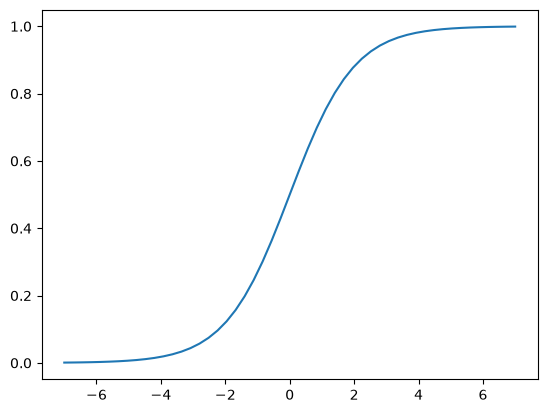

In [20]:
z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))
plt.show()

### Linear regression vs. logistic regression

In [62]:
def linear_regression(xi):
    result = w0

    for j in range(len(w)):
        result = result + xi[j] * w[j]

    return result


def logistic_regression(xi):
    score = w0

    for j in range(len(w)):
        score = score + xi[j] * w[j]

    result = sigmoid(score)
    return result

## Training logistic regression with Scikit-Learn

In [63]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear')
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

### Weights and bias

In [64]:
model.coef_[0].round(3)

array([ 0.556, -0.151, -0.54 ,  0.012, -0.146,  0.018, -0.11 , -0.041,
       -0.039, -0.096, -0.36 ,  0.337, -0.11 ,  0.001, -0.239,  0.132,
       -0.027,  0.102, -0.11 , -0.126,  0.244, -0.11 , -0.268, -0.229,
        0.095, -0.114, -0.02 , -0.085, -0.181,  0.258, -0.126,  0.132,
       -0.266,  0.194, -0.145, -0.11 ,  0.121, -0.082, -0.11 ,  0.058,
        0.21 , -0.11 , -0.234, -0.058,  0.   ])

In [65]:
model.intercept_[0]

np.float64(-0.13429227888146675)

In [66]:
weights = pd.Series(model.coef_[0].round(3), index=dv.get_feature_names_out())
weights.sort_values()

contract=two_year                         -0.540
internetservice=dsl                       -0.360
onlinesecurity=yes                        -0.268
phoneservice=yes                          -0.266
multiplelines=no                          -0.239
techsupport=yes                           -0.234
paperlessbilling=no                       -0.229
paymentmethod=credit_card_(automatic)     -0.181
contract=one_year                         -0.151
dependents=yes                            -0.146
streamingmovies=no                        -0.145
onlinebackup=yes                          -0.126
paymentmethod=mailed_check                -0.126
partner=no                                -0.114
onlinebackup=no_internet_service          -0.110
onlinesecurity=no_internet_service        -0.110
streamingmovies=no_internet_service       -0.110
internetservice=no                        -0.110
streamingtv=no_internet_service           -0.110
techsupport=no_internet_service           -0.110
deviceprotection=no_

### Hard and soft predictions

In [67]:
model.predict(X_train)

array([0, 0, 1, ..., 0, 1, 0], shape=(5634,))

In [68]:
model.predict_proba(X_train)

array([[0.92231148, 0.07768852],
       [0.83783797, 0.16216203],
       [0.28856363, 0.71143637],
       ...,
       [0.79138543, 0.20861457],
       [0.2105706 , 0.7894294 ],
       [0.97071276, 0.02928724]], shape=(5634, 2))

### Apply the model to the validation data

In [69]:
y_pred = model.predict_proba(X_val)[:, 1]
y_pred

array([0.72340153, 0.05454576, 0.00568432, ..., 0.04790322, 0.01749465,
       0.51307608], shape=(1409,))

In [70]:
churn_decision = (y_pred >= 0.5)
churn_decision

array([ True, False, False, ..., False, False,  True], shape=(1409,))

In [71]:
churn_decision.sum()

np.int64(333)

In [72]:
df_val[churn_decision][['customerid', 'contract', 'tenure', 'internetservice', 'monthlycharges']].head()

,customerid,contract,tenure,internetservice,monthlycharges
185,1024-guald,month-to-month,1,dsl,24.80
1807,6910-hadcm,month-to-month,1,fiber_optic,76.35
3801,5914-dvbwj,month-to-month,18,fiber_optic,85.45
6179,6328-zpbgn,month-to-month,11,fiber_optic,95.15
4640,1853-udxbw,month-to-month,1,fiber_optic,70.00


In [73]:
df_val[churn_decision].customerid

185     1024-guald
1807    6910-hadcm
3801    5914-dvbwj
6179    6328-zpbgn
4640    1853-udxbw
           ...    
2453    1197-bvmvg
3773    8260-ngfny
926     7074-ievoj
5481    8473-vuvjn
1161    5868-czjdr
Name: customerid, Length: 333, dtype: str

## Calculate the accuracy

In [74]:
y_val

array([1, 0, 0, ..., 0, 0, 1], shape=(1409,))

In [75]:
churn_decision.astype(int)

array([1, 0, 0, ..., 0, 0, 1], shape=(1409,))

In [76]:
(y_val == churn_decision).mean()

np.float64(0.8168914123491838)

### How does this line work?

In [77]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = churn_decision.astype(int)
df_pred['actual'] = y_val
df_pred['correct'] = df_pred.prediction == df_pred.actual
df_pred.head(8)

,probability,prediction,actual,correct
0,0.723402,1,1,True
1,0.054546,0,0,True
2,0.005684,0,0,True
3,0.622391,1,1,True
4,0.007115,0,0,True
5,0.287064,0,1,False
6,0.061160,0,0,True
7,0.004458,0,0,True


In [78]:
df_pred.correct.mean()

np.float64(0.8168914123491838)

## Confusion Matrix

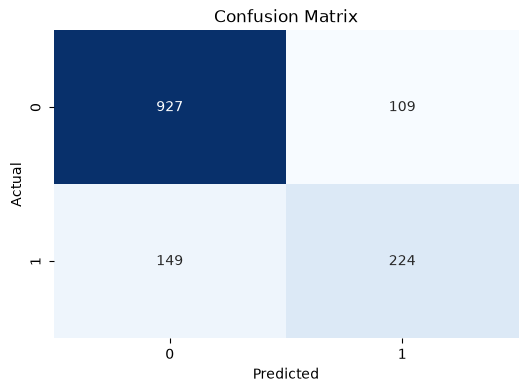

In [79]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_val, churn_decision)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## Bundling and saving the model

In [80]:
from sklearn.pipeline import make_pipeline

pipeline = make_pipeline(
    DictVectorizer(sparse=False),
    LogisticRegression(solver='liblinear')
)
pipeline.fit(train_dicts, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [81]:
y_pred = pipeline.predict_proba(val_dicts)[:, 1]
((y_pred >= 0.5) == y_val).mean()

np.float64(0.8168914123491838)

In [82]:
import pickle

with open(MODEL_PATH, 'wb') as f_out:
    pickle.dump(pipeline, f_out)

In [83]:
with open(MODEL_PATH, 'rb') as f_in:
    loaded_model = pickle.load(f_in)

customer = val_dicts[0]
customer

{'gender': 'female',
 'seniorcitizen': 0,
 'partner': 'yes',
 'dependents': 'no',
 'phoneservice': 'no',
 'multiplelines': 'no_phone_service',
 'internetservice': 'dsl',
 'onlinesecurity': 'no',
 'onlinebackup': 'no',
 'deviceprotection': 'no',
 'techsupport': 'no',
 'streamingtv': 'no',
 'streamingmovies': 'no',
 'contract': 'month-to-month',
 'paperlessbilling': 'yes',
 'paymentmethod': 'electronic_check',
 'tenure': 1,
 'monthlycharges': 24.8,
 'totalcharges': 24.8}

In [84]:
loaded_model.predict_proba([customer])[0, 1]

np.float64(0.7234015282022489)

In [85]:
y_val[0]

np.int64(1)